 # Predictive Maintenance: Machine Failure Classification



 > **Term project:** a reproducible comparison of feature-selection strategies and machine-learning classifiers for predictive maintenance failure detection.



 ## 1. Project Objective



 This project investigates whether selecting a smaller set of machine sensors can produce a useful classifier for the `Machine failure` target in the AI4I 2020 predictive-maintenance dataset. The primary metric is positive-class failure F1, supported by failure recall, precision, balanced accuracy, missed failures, and false alarms.



 ## 2. Experiment Roadmap



 The notebook follows one fixed workflow from start to finish:



 1. **Load and explore the data.** Inspect columns, data types, missing values, duplicates, class balance, and simple relationships.

 2. **Prepare predictors and target.** Keep the 6 usable raw sensor variables, encode `Type`, and exclude identifiers and failure-cause columns that would leak the target.

 3. **Create fixed data splits.** Use stratified 70% training, 15% validation, and 15% test splits. The test split is hidden until the final step.

 4. **Configure experiment settings.** Set the number of selected features, selector models, PCA variance threshold, and cross-validation folds in one place.

 5. **Fit feature-selection methods on training data only.** Compare ANOVA, Pearson correlation, adapted Lasso, RFE, forward/backward selection, and PCA.

 6. **Screen model combinations.** Fit the baseline and selected-feature models on training data and compare them on validation data.

 7. **Choose three finalists & test Stacking.** Select the top three distinct model architectures using validation failure F1, recall, and precision, and test whether combining them into a Stacking Ensemble improves performance.

 8. **Fine-tune finalists.** Search focused hyperparameter grids using five-fold stratified cross-validation on the training split.

 9. **Choose the tuned winner & refit.** Compare the tuned finalists on validation performance, then refit the winning configuration on the combined training and validation data (85%).

 10. **Evaluate once on the test set.** Report the final unseen-data result, confusion matrix, ROC & AUC curve, missed failures, and false alarms.



 ## 3. Important Interpretation Rule



 The validation tables answer **which approach should be selected**. The final test table answers **how the already-selected approach performs on unseen data**. A test score must not be used to choose a different winner.

 ## 4. Load Data

In [46]:
# Reproducibility and common imports
import os
import random

RANDOM_STATE = 55
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(RANDOM_STATE)


In [47]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "ai4i2020.csv"

# Load the latest version
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "stephanmatzka/predictive-maintenance-dataset-ai4i-2020",
    file_path,
)

print("First 5 records:")
display(df.head())


First 5 records:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


 ## 5. Explore



 Inspect the AI4I 2020 predictive-maintenance dataset structure, data types, missing values, duplicates, class balance, and physical sensor relationships.

In [48]:
display(df.columns)


Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [49]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [50]:
print(df["Type"])


0       M
1       L
2       L
3       L
4       L
       ..
9995    M
9996    H
9997    M
9998    H
9999    M
Name: Type, Length: 10000, dtype: object


In [51]:
display(df)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [52]:
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate UDIs:", df["UDI"].duplicated().sum())


Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Duplicate rows: 0
Duplicate UDIs: 0


Machine failure
0    9661
1     339
Name: count, dtype: int64 
 Machine failure
0    96.61
1     3.39
Name: count, dtype: float64


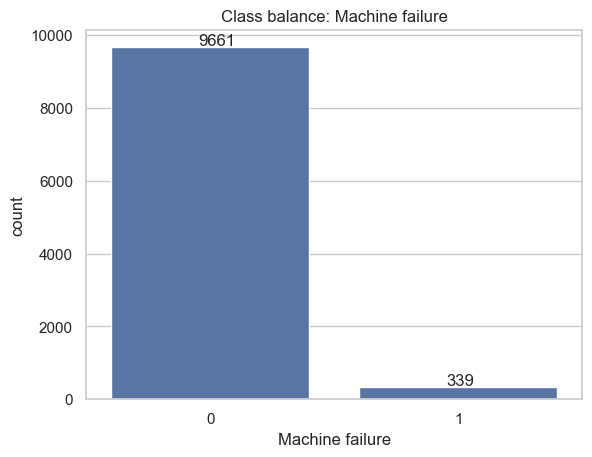

In [53]:
counts = df["Machine failure"].value_counts()
print(counts, "\n", (counts / len(df) * 100).round(2))

ax = sns.countplot(x="Machine failure", data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + 0.35, p.get_height() + 50))
plt.title("Class balance: Machine failure")
plt.show()


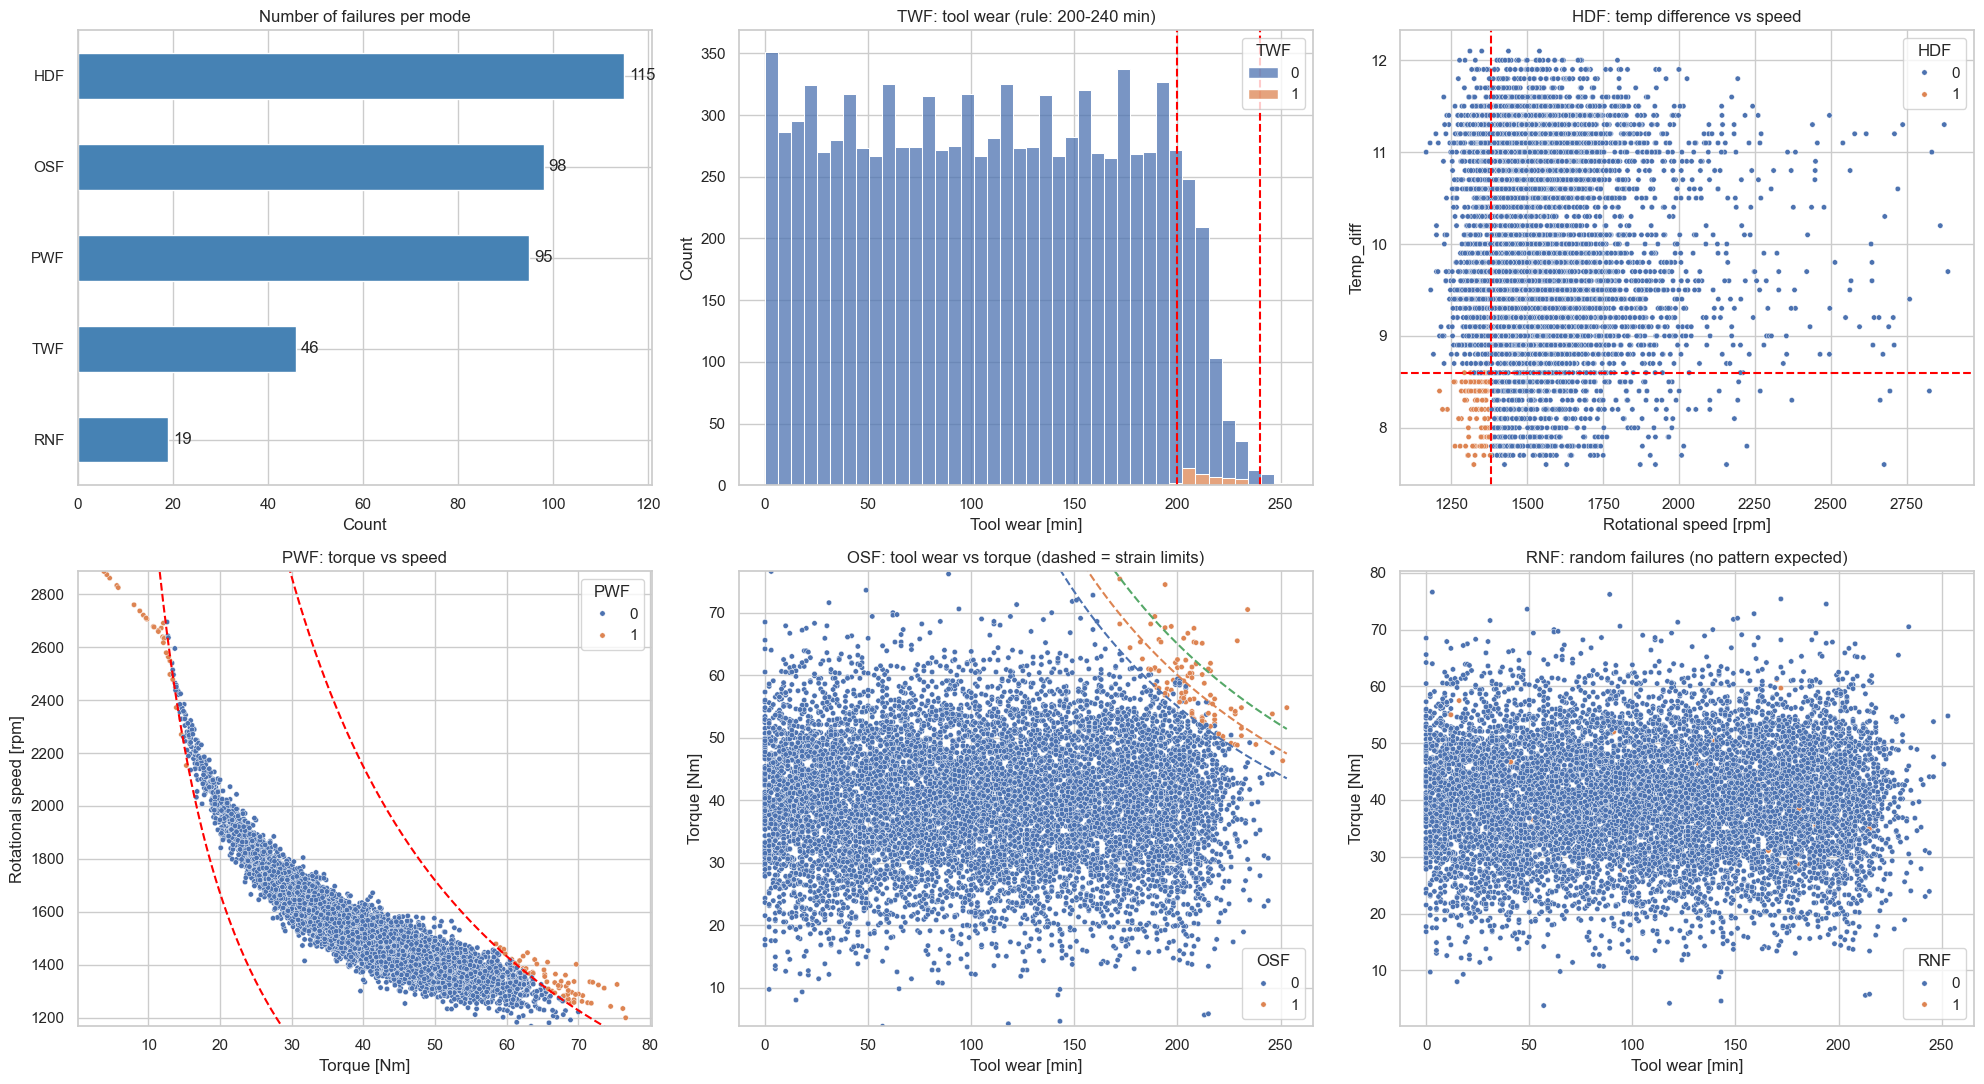

In [54]:
sns.set_theme(style="whitegrid")

# Original column names (used for EDA visualization only)
air, proc = "Air temperature [K]", "Process temperature [K]"
rpm, tq, wear = "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Temporary helper columns for plotting physical failure boundaries in EDA
eda_df = df.copy()
eda_df["Temp_diff"] = eda_df[proc] - eda_df[air]
eda_df["Power"] = eda_df[tq] * eda_df[rpm] * 2 * np.pi / 60
eda_df["Strain"] = eda_df[wear] * eda_df[tq]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes = axes.flatten()

# 1) Count of each failure mode
mode_counts = eda_df[modes].sum().sort_values()
mode_counts.plot(kind="barh", ax=axes[0], color="steelblue")
for i, v in enumerate(mode_counts):
    axes[0].text(v + 1, i, int(v), va="center")
axes[0].set_title("Number of failures per mode")
axes[0].set_xlabel("Count")

# 2) TWF: tool wear (failures expected between 200 and 240 min)
sns.histplot(data=eda_df, x=wear, hue="TWF", bins=40, multiple="stack", ax=axes[1])
axes[1].axvline(200, color="red", ls="--")
axes[1].axvline(240, color="red", ls="--")
axes[1].set_title("TWF: tool wear (rule: 200-240 min)")

# 3) HDF: temperature difference < 8.6 K and speed < 1380 rpm
sns.scatterplot(data=eda_df, x=rpm, y="Temp_diff", hue="HDF", s=15, ax=axes[2])
axes[2].axhline(8.6, color="red", ls="--")
axes[2].axvline(1380, color="red", ls="--")
axes[2].set_title("HDF: temp difference vs speed")

# 4) PWF: power < 3500 W or > 9000 W
sns.scatterplot(data=eda_df, x=tq, y=rpm, hue="PWF", s=15, ax=axes[3])
axes[3].set_title("PWF: torque vs speed")
axes[3].set_ylim(eda_df[rpm].min(), eda_df[rpm].max())
t = np.linspace(max(eda_df[tq].min(), 1), eda_df[tq].max(), 300)
for P in (3500, 9000):
    axes[3].plot(t, P * 60 / (2 * np.pi * t), color="red", ls="--")

# 5) OSF: strain above 11000 (L), 12000 (M), 13000 (H)
sns.scatterplot(data=eda_df, x=wear, y=tq, hue="OSF", s=15, ax=axes[4])
w = np.linspace(max(eda_df[wear].min(), 1), eda_df[wear].max(), 300)
for lim in (11000, 12000, 13000):
    axes[4].plot(w, lim / w, ls="--", label=f"{lim}")
axes[4].set_ylim(eda_df[tq].min(), eda_df[tq].max())
axes[4].set_title("OSF: tool wear vs torque (dashed = strain limits)")

# 6) RNF: random by design, so no rule region is expected
sns.scatterplot(data=eda_df, x=wear, y=tq, hue="RNF", s=15, ax=axes[5])
axes[5].set_title("RNF: random failures (no pattern expected)")

plt.tight_layout()
plt.show()


In [55]:
print(np.unique(df["Machine failure"]))


[0 1]


 ## 6. Pre-processing and Data Splitting



 Select the 6 usable raw predictor columns, encode machine `Type` (`L=0, M=1, H=2`), define the target, and create fixed stratified training (70%), validation (15%), and test (15%) splits. Identifiers (`UDI`, `Product ID`) and failure-cause columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) are excluded so they cannot leak the target label.

In [56]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

x = df[features].copy()
y = df["Machine failure"]
print("Predictor shape:", x.shape)
print("Target shape:   ", y.shape)


Predictor shape: (10000, 6)
Target shape:    (10000,)


In [57]:
# Encode ordinal quality type from string to integer
x["Type"] = x["Type"].map({"L": 0, "M": 1, "H": 2})
display(x.head())


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,1,298.1,308.6,1551,42.8,0
1,0,298.2,308.7,1408,46.3,3
2,0,298.1,308.5,1498,49.4,5
3,0,298.2,308.6,1433,39.5,7
4,0,298.2,308.7,1408,40.0,9


In [58]:
print("Unique Type values:", x["Type"].unique())
print(x.dtypes)
print("Missing values:\n", x.isna().sum())


Unique Type values: [1 0 2]
Type                         int64
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object
Missing values:
 Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64


In [59]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

# Keep the test set untouched until the final evaluation.
x_train, x_temp, y_train, y_temp = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp,
)

print(f"Training samples:   {len(x_train)}")
print(f"Validation samples: {len(x_val)}")
print(f"Test samples:       {len(x_test)}")


Training samples:   7000
Validation samples: 1500
Test samples:       1500


In [60]:
# Check class balance in the development splits. The test labels remain unused until final evaluation.
display(
    pd.DataFrame({
        "Training": y_train.value_counts(),
        "Validation": y_val.value_counts(),
    }).fillna(0).astype(int)
)


,Training,Validation
Machine failure,,
0,6763,1449
1,237,51


 ## 7. Master Experiment Configuration



 Change the variables in the cell below and re-run the notebook to test different feature counts, RFE/SFS wrapper selectors, PCA variance thresholds, or finalist selection rules.

In [61]:
# ── Master Experiment Configuration ──────────────────────────────────
# Note: RANDOM_STATE = 55 is already set in Section 4 and shared across the notebook.
# Note: All configurations below are used to control the behavior of the experiment.

NUMBER_OF_FEATURES = 4            # Features kept by ANOVA / Correlation / Lasso / RFE / SFS (out of 6)

RFE_SELECTOR_MODEL = "Logistic Regression"
# Options: "Logistic Regression", "Linear SVC", "Decision Tree", "Random Forest"

SFS_SELECTOR_MODEL = "Decision Tree"
# Options: "Logistic Regression", "Decision Tree", "Random Forest"
# (Tip: "Decision Tree" or "Logistic Regression" runs much faster than 200-tree "Random Forest")

PCA_VARIANCE = 0.95               # Cumulative training variance PCA must retain
CV_FOLDS     = 5                  # Folds for GridSearchCV and SFS

UNIQUE_FINALIST_MODELS = True       # True  -> Top 3 finalists must be 3 distinct model architectures
                                    # False -> Allow same model architecture with different feature sets

# Consistent sort order for ALL validation comparison tables
PRIMARY_SORT_METRICS = [
    "Validation failure F1",
    "Validation failure recall",
    "Validation failure precision",
    "Validation accuracy",
]


 ## 8. Modelling and Evaluation Setup



 The baseline classifiers compared across every feature-selection strategy are:



 - **Support Vector Classifier (SVC)** (using RBF kernel for baseline screening; Linear, Poly, and RBF tested in tuning)

 - **Logistic Regression**

 - **Decision Tree** (Gini impurity)

 - **Random Forest** (Bagging ensemble)

 - **Gradient Boosting Classifier** (Boosting ensemble)

 - **Neural Network MLP** (Multilayer Perceptron)



 *(Note: **Stacking Ensemble** is evaluated dynamically in Section 15 by combining the Top 3 screening models).*



 ### 8.1 Experimental Rules & Metrics

 - **No feature selection** (all 6 sensors) is the reference baseline.

 - Filter, Embedded, and Wrapper methods retain `NUMBER_OF_FEATURES` sensors so the screening comparison is controlled.

 - All feature selectors and scalers are fitted on **training data only** (`x_train`).

 - Because machine failures are rare (3.39%), accuracy is misleading. All tables are ranked by `PRIMARY_SORT_METRICS`:

   1. **Validation failure F1** (balance between precision and recall)

   2. **Validation failure recall** (minimizing missed failures / false negatives)

   3. **Validation failure precision** (minimizing false alarms / false positives)

   4. **Validation accuracy** (tie-breaker)

In [62]:
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.feature_selection import RFE, SelectKBest, SequentialFeatureSelector, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

selection_models = {
    "SVC": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000, random_state=RANDOM_STATE),
    ),
}

def evaluate_selected_features(selection_name, selected_features):
    """Fit all screening models on x_train[selected_features] and evaluate on x_val."""
    rows = []
    for model_name, model in selection_models.items():
        fitted_model = clone(model)
        fitted_model.fit(x_train[selected_features], y_train)
        predictions = fitted_model.predict(x_val[selected_features])
        report = classification_report(
            y_val, predictions, output_dict=True, zero_division=0
        )
        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()
        rows.append({
            "Feature selection": selection_name,
            "Features": ", ".join(selected_features),
            "Model": model_name,
            "Validation accuracy": report["accuracy"],
            "Validation balanced accuracy": balanced_accuracy_score(y_val, predictions),
            "Validation failure precision": report["1"]["precision"],
            "Validation failure recall": report["1"]["recall"],
            "Validation failure F1": report["1"]["f1-score"],
            "Validation missed failures": fn,
            "Validation false alarms": fp,
        })
    return pd.DataFrame(rows)


 ## 9. No Feature Selection: Baseline



 Evaluate all 6 models using all 6 original sensor predictors. This serves as our benchmark before removing any features.

In [63]:
baseline_results = evaluate_selected_features(
    "No feature selection", x_train.columns.tolist()
)
display(baseline_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.986000,0.841412,0.875000,0.686275,0.769231,16,5
4,No feature selection,"Type, Air temperature [K], Process temperature...",Gradient Boosting,0.984667,0.812345,0.888889,0.627451,0.735632,19,4
3,No feature selection,"Type, Air temperature [K], Process temperature...",Random Forest,0.984667,0.783969,0.966667,0.568627,0.716049,22,1
2,No feature selection,"Type, Air temperature [K], Process temperature...",Decision Tree,0.972667,0.777757,0.604167,0.568627,0.585859,22,19
0,No feature selection,"Type, Air temperature [K], Process temperature...",SVC,0.924667,0.904254,0.296053,0.882353,0.443350,6,107
1,No feature selection,"Type, Air temperature [K], Process temperature...",Logistic Regression,0.830000,0.826879,0.145833,0.823529,0.247788,9,246


 ## 10. Filter Methods



 Filter methods score each sensor independently based on statistical tests against the target before any classifier is trained.



 ### 10.1 ANOVA F-Test Filter Selection

 ANOVA (`f_classif`) measures whether the mean of each sensor differs significantly between normal machines (`0`) and failed machines (`1`), keeping the top `NUMBER_OF_FEATURES` sensors.

In [64]:
anova_filter = SelectKBest(f_classif, k=NUMBER_OF_FEATURES)
anova_filter.fit(x_train, y_train)
anova_features = x_train.columns[anova_filter.get_support()].tolist()

print(f"ANOVA-selected features ({NUMBER_OF_FEATURES}):", anova_features)
anova_results = evaluate_selected_features("ANOVA", anova_features)
display(anova_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


ANOVA-selected features (4): ['Air temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
4,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
3,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Random Forest,0.972667,0.654792,0.727273,0.313725,0.438356,35,6
0,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119
2,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Decision Tree,0.961333,0.658385,0.414634,0.333333,0.369565,34,24
1,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Logistic Regression,0.811333,0.788840,0.125806,0.764706,0.216066,12,271


 ### 10.2 Pearson Correlation Selection

 Pearson's $R$ measures the absolute linear correlation between each sensor and the binary `Machine failure` target on the training split.

In [65]:
correlation_scores = x_train.apply(
    lambda column: abs(np.corrcoef(column, y_train)[0, 1])
).sort_values(ascending=False)
correlation_features = correlation_scores.head(NUMBER_OF_FEATURES).index.tolist()

print(f"Pearson-selected features ({NUMBER_OF_FEATURES}):", correlation_features)
display(correlation_scores.to_frame("absolute Pearson correlation"))

correlation_results = evaluate_selected_features(
    "Pearson correlation", correlation_features
)
display(correlation_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


Pearson-selected features (4): ['Torque [Nm]', 'Tool wear [min]', 'Air temperature [K]', 'Rotational speed [rpm]']


,absolute Pearson correlation
Torque [Nm],0.190886
Tool wear [min],0.098262
Air temperature [K],0.092141
Rotational speed [rpm],0.047755
Process temperature [K],0.046375
Type,0.038291


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",MLP,0.979333,0.771749,0.777778,0.549020,0.643678,23,8
4,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
0,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119
3,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",Random Forest,0.971333,0.635185,0.700000,0.274510,0.394366,37,6
2,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",Decision Tree,0.961333,0.658385,0.414634,0.333333,0.369565,34,24
1,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",Logistic Regression,0.811333,0.788840,0.125806,0.764706,0.216066,12,271


 ## 11. Embedded Methods (Regularization)



 Embedded methods perform feature selection as part of the model optimization objective (penalizing large weights).



 ### 11.1 Adapted Lasso (L1) Selection

 Lasso adds an $L_1$ penalty ($\lambda \sum \vert{}w_i\vert{}$) that shrinks weak sensor coefficients toward zero. We select the `NUMBER_OF_FEATURES` sensors with the largest non-zero $L_1$ coefficients.

In [66]:
adapted_lasso = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1", solver="liblinear", C=0.1,
        max_iter=2000, random_state=RANDOM_STATE,
    ),
)
adapted_lasso.fit(x_train, y_train)

lasso_coefficients = np.abs(adapted_lasso[-1].coef_).ravel()
nonzero_lasso = np.flatnonzero(lasso_coefficients > 1e-8)
strongest_lasso = np.argsort(lasso_coefficients)[::-1]
lasso_indices = [
    index for index in strongest_lasso if index in nonzero_lasso
][:NUMBER_OF_FEATURES]

if lasso_indices:
    lasso_features = x_train.columns[lasso_indices].tolist()
else:
    lasso_features = x_train.columns[
        np.argsort(lasso_coefficients)[-NUMBER_OF_FEATURES:]
    ].tolist()

print(f"Adapted Lasso-selected features ({NUMBER_OF_FEATURES}):", lasso_features)
display(
    pd.Series(lasso_coefficients, index=x_train.columns)
    .sort_values(ascending=False)
    .to_frame("absolute L1 coefficient")
)

lasso_results = evaluate_selected_features("Adapted Lasso", lasso_features)
display(lasso_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


Adapted Lasso-selected features (4): ['Torque [Nm]', 'Rotational speed [rpm]', 'Air temperature [K]', 'Tool wear [min]']


,absolute L1 coefficient
Torque [Nm],2.296194
Rotational speed [rpm],1.663492
Air temperature [K],0.926099
Tool wear [min],0.633555
Process temperature [K],0.483274
Type,0.142156


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",MLP,0.978667,0.761945,0.771429,0.529412,0.627907,24,8
4,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
0,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119
3,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",Random Forest,0.971333,0.635185,0.700000,0.274510,0.394366,37,6
2,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",Decision Tree,0.961333,0.658385,0.414634,0.333333,0.369565,34,24
1,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",Logistic Regression,0.811333,0.788840,0.125806,0.764706,0.216066,12,271


 ### 11.2 Ridge (L2), Lasso (L1), and Elastic Net Comparison

 Ridge ($L_2$) shrinks coefficients without zeroing them out, while Elastic Net combines $L_1$ and $L_2$ penalties to handle correlated sensors (like Air and Process Temperature). Here we compare all three regularization penalties on Logistic Regression.

In [67]:
regularization_models = {
    "Ridge (L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2", class_weight="balanced",
            max_iter=2000, random_state=RANDOM_STATE,
        ),
    ),
    "Lasso (L1)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1", solver="liblinear",
            class_weight="balanced", max_iter=2000,
            random_state=RANDOM_STATE,
        ),
    ),
    "Elastic Net (L1 + L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="elasticnet", solver="saga", l1_ratio=0.5,
            class_weight="balanced", max_iter=3000,
            random_state=RANDOM_STATE,
        ),
    ),
}

regularization_rows = []
for model_name, model in regularization_models.items():
    model.fit(x_train, y_train)
    predictions = model.predict(x_val)
    report = classification_report(
        y_val, predictions, output_dict=True, zero_division=0
    )
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()
    regularization_rows.append({
        "Regularization": model_name,
        "Validation accuracy": report["accuracy"],
        "Validation balanced accuracy": balanced_accuracy_score(y_val, predictions),
        "Validation failure precision": report["1"]["precision"],
        "Validation failure recall": report["1"]["recall"],
        "Validation failure F1": report["1"]["f1-score"],
        "Validation missed failures": fn,
        "Validation false alarms": fp,
    })

regularization_results = pd.DataFrame(regularization_rows).sort_values(
    PRIMARY_SORT_METRICS, ascending=False
)
display(regularization_results)


c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,Regularization,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,Ridge (L2),0.830000,0.826879,0.145833,0.823529,0.247788,9,246
1,Lasso (L1),0.830000,0.826879,0.145833,0.823529,0.247788,9,246
2,Elastic Net (L1 + L2),0.828667,0.665388,0.097656,0.490196,0.162866,26,231


 ## 12. Wrapper Methods



 Wrapper methods use a machine learning model to evaluate subsets of features:

 - **Recursive Feature Elimination (RFE):** Fits a model and iteratively prunes the weakest features based on coefficients or feature importances.

 - **Forward Selection (SFS):** Starts with 0 features and greedily adds the sensor that maximizes cross-validated F1.

 - **Backward Selection (SFS):** Starts with all 6 features and greedily removes the sensor whose removal hurts cross-validated F1 the least.



 ### 12.1 Recursive Feature Elimination (RFE)

 We first standardize `x_train` so linear and SVM coefficients are not distorted by sensor units (e.g., RPM vs. Torque), then compare four RFE base estimators. The active `RFE_SELECTOR_MODEL` from the Master Config is used for model screening.

In [68]:
scaler_rfe = StandardScaler()
x_train_s_df = pd.DataFrame(
    scaler_rfe.fit_transform(x_train),
    columns=x_train.columns,
    index=x_train.index,
)

rfe_selectors = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Linear SVC": SVC(
        kernel="linear", class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
}

rfe_selected_features = {}
for selector_name, estimator in rfe_selectors.items():
    selector = RFE(estimator, n_features_to_select=NUMBER_OF_FEATURES)
    selector.fit(x_train_s_df, y_train)
    rfe_selected_features[selector_name] = (
        x_train.columns[selector.get_support()].tolist()
    )

print("Features selected by each RFE base estimator:")
display(
    pd.DataFrame.from_dict(
        rfe_selected_features,
        orient="index",
        columns=[f"Feature {i + 1}" for i in range(NUMBER_OF_FEATURES)],
    )
)


Features selected by each RFE base estimator:


,Feature 1,Feature 2,Feature 3,Feature 4
Logistic Regression,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm]
Linear SVC,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm]
Decision Tree,Air temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Random Forest,Air temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]


In [69]:
rfe_features = rfe_selected_features[RFE_SELECTOR_MODEL]
print(f"Active RFE selector ({RFE_SELECTOR_MODEL}) features:", rfe_features)

rfe_results = evaluate_selected_features("RFE", rfe_features)
display(rfe_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


Active RFE selector (Logistic Regression) features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]']


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,RFE,"Air temperature [K], Process temperature [K], ...",MLP,0.981333,0.820079,0.767442,0.647059,0.702128,18,10
3,RFE,"Air temperature [K], Process temperature [K], ...",Random Forest,0.983333,0.773820,0.933333,0.549020,0.691358,23,2
4,RFE,"Air temperature [K], Process temperature [K], ...",Gradient Boosting,0.983333,0.764361,0.964286,0.529412,0.683544,24,1
2,RFE,"Air temperature [K], Process temperature [K], ...",Decision Tree,0.972000,0.767954,0.595745,0.549020,0.571429,23,19
0,RFE,"Air temperature [K], Process temperature [K], ...",SVC,0.898667,0.834044,0.217877,0.764706,0.339130,12,140
1,RFE,"Air temperature [K], Process temperature [K], ...",Logistic Regression,0.813333,0.818252,0.134185,0.823529,0.230769,9,271


 ### 12.2 Forward and Backward Sequential Feature Selection (SFS)

 Both wrapper methods evaluate feature subsets using `CV_FOLDS`-fold cross-validation with the configured `SFS_SELECTOR_MODEL`.

In [70]:
sfs_model_lookup = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
        ),
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=200, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1,
        ),
    ),
}

sfs_estimator = sfs_model_lookup[SFS_SELECTOR_MODEL]
print(f"Running Forward & Backward SFS using estimator: {SFS_SELECTOR_MODEL}")

forward_selector = SequentialFeatureSelector(
    sfs_estimator,
    n_features_to_select=NUMBER_OF_FEATURES,
    direction="forward",
    scoring="f1",
    cv=CV_FOLDS,
    n_jobs=-1,
)
backward_selector = SequentialFeatureSelector(
    sfs_estimator,
    n_features_to_select=NUMBER_OF_FEATURES,
    direction="backward",
    scoring="f1",
    cv=CV_FOLDS,
    n_jobs=-1,
)

forward_selector.fit(x_train, y_train)
backward_selector.fit(x_train, y_train)
forward_features = x_train.columns[forward_selector.get_support()].tolist()
backward_features = x_train.columns[backward_selector.get_support()].tolist()

print("Forward-selected features: ", forward_features)
print("Backward-selected features:", backward_features)

forward_results = evaluate_selected_features("Forward selection", forward_features)
backward_results = evaluate_selected_features("Backward selection", backward_features)

display(forward_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))
display(backward_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


Running Forward & Backward SFS using estimator: Decision Tree
Forward-selected features:  ['Air temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Backward-selected features: ['Air temperature [K]', 'Process temperature [K]', 'Torque [Nm]', 'Tool wear [min]']


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
4,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
3,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",Random Forest,0.972667,0.654792,0.727273,0.313725,0.438356,35,6
0,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119
2,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",Decision Tree,0.961333,0.658385,0.414634,0.333333,0.369565,34,24
1,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",Logistic Regression,0.811333,0.788840,0.125806,0.764706,0.216066,12,271


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,Backward selection,"Air temperature [K], Process temperature [K], ...",MLP,0.979333,0.762290,0.794118,0.529412,0.635294,24,7
4,Backward selection,"Air temperature [K], Process temperature [K], ...",Gradient Boosting,0.974667,0.712581,0.709677,0.431373,0.536585,29,9
0,Backward selection,"Air temperature [K], Process temperature [K], ...",SVC,0.900667,0.910750,0.244792,0.921569,0.386831,4,145
2,Backward selection,"Air temperature [K], Process temperature [K], ...",Decision Tree,0.959333,0.676268,0.395833,0.372549,0.383838,32,29
3,Backward selection,"Air temperature [K], Process temperature [K], ...",Random Forest,0.968000,0.633459,0.560000,0.274510,0.368421,37,11
1,Backward selection,"Air temperature [K], Process temperature [K], ...",Logistic Regression,0.758667,0.780498,0.104326,0.803922,0.184685,10,352


 ## 13. Dimensionality Reduction



 ### 13.1 Principal Component Analysis (PCA)

 Unlike feature selection (which drops original sensors), PCA projects all 6 standardized sensors into orthogonal principal components that retain `PCA_VARIANCE` (95%) of the training variance.

Explained variance ratio: [0.32  0.306 0.17  0.164 0.021 0.02 ]
Cumulative variance:      [0.32  0.626 0.795 0.959 0.98  1.   ]


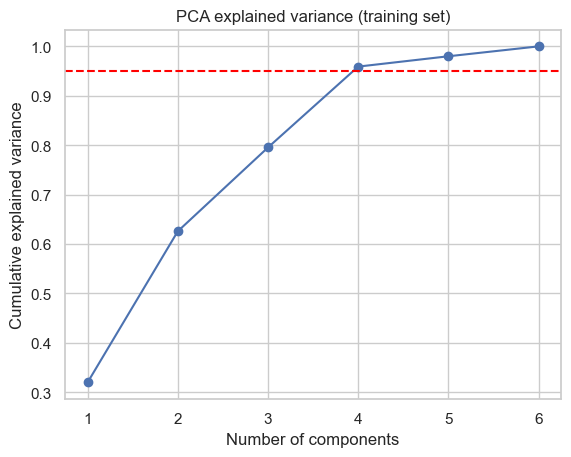

In [71]:
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_val_s = scaler.transform(x_val)

pca_full = PCA(random_state=RANDOM_STATE).fit(x_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
print("Explained variance ratio:", np.round(pca_full.explained_variance_ratio_, 3))
print("Cumulative variance:     ", np.round(cum, 3))

plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(PCA_VARIANCE, color="red", ls="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance (training set)")
plt.show()


In [72]:
pca = PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE)
x_train_pca = pca.fit_transform(x_train_s)
x_val_pca = pca.transform(x_val_s)
print("Components kept:", pca.n_components_)


Components kept: 4


In [73]:
pca_rows = []
for model_name, model in selection_models.items():
    fitted = clone(model)
    fitted.fit(x_train_pca, y_train)
    predictions = fitted.predict(x_val_pca)
    report = classification_report(
        y_val, predictions, output_dict=True, zero_division=0
    )
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()
    pca_rows.append({
        "Feature selection": "PCA",
        "Features": f"{pca.n_components_} components",
        "Model": model_name,
        "Validation accuracy": report["accuracy"],
        "Validation balanced accuracy": balanced_accuracy_score(y_val, predictions),
        "Validation failure precision": report["1"]["precision"],
        "Validation failure recall": report["1"]["recall"],
        "Validation failure F1": report["1"]["f1-score"],
        "Validation missed failures": fn,
        "Validation false alarms": fp,
    })

pca_results = pd.DataFrame(pca_rows)
print("PCA evaluation:")
display(pca_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


PCA evaluation:


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,PCA,4 components,MLP,0.976000,0.675435,0.857143,0.352941,0.500000,33,3
4,PCA,4 components,Gradient Boosting,0.973333,0.683514,0.703704,0.372549,0.487179,32,8
3,PCA,4 components,Random Forest,0.970000,0.643953,0.625000,0.294118,0.400000,36,9
2,PCA,4 components,Decision Tree,0.962667,0.668534,0.439024,0.352941,0.391304,33,23
0,PCA,4 components,SVC,0.878000,0.861182,0.197248,0.843137,0.319703,8,175
1,PCA,4 components,Logistic Regression,0.702667,0.751512,0.085954,0.803922,0.155303,10,436


 ## 14. Validation Comparison and Candidate Screening



 We now combine all validation results from every feature-selection method × model combination.

 - **Why we do this:** Screening lets us quickly compare all combinations using default hyperparameters on the Validation set ("practice exam").

 - The Test set ("final exam") remains completely hidden.

In [74]:
result_tables = {
    "No feature selection": baseline_results,
    "ANOVA": anova_results,
    "Pearson correlation": correlation_results,
    "Adapted Lasso": lasso_results,
    "Forward selection": forward_results,
    "Backward selection": backward_results,
    "RFE": rfe_results,
    "PCA": pca_results,
}

all_comparison_results = pd.concat(
    list(result_tables.values()),
    ignore_index=True,
)

selection_order = list(result_tables)
all_comparison_results["Feature selection"] = pd.Categorical(
    all_comparison_results["Feature selection"],
    categories=selection_order,
    ordered=True,
)

grouped_ranking = (
    all_comparison_results.sort_values(
        ["Feature selection"] + PRIMARY_SORT_METRICS + ["Model"],
        ascending=[True, False, False, False, False, True],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

print("Validation ranking within each feature-selection method:")
display(grouped_ranking)

best_per_selection = (
    grouped_ranking
    .groupby("Feature selection", observed=True, sort=False)
    .head(1)
    .sort_values(
        PRIMARY_SORT_METRICS + ["Model"],
        ascending=[False, False, False, False, True],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

print("Best validation model from each feature-selection method:")
display(best_per_selection)


Validation ranking within each feature-selection method:


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.986000,0.841412,0.875000,0.686275,0.769231,16,5
1,No feature selection,"Type, Air temperature [K], Process temperature...",Gradient Boosting,0.984667,0.812345,0.888889,0.627451,0.735632,19,4
2,No feature selection,"Type, Air temperature [K], Process temperature...",Random Forest,0.984667,0.783969,0.966667,0.568627,0.716049,22,1
3,No feature selection,"Type, Air temperature [K], Process temperature...",Decision Tree,0.972667,0.777757,0.604167,0.568627,0.585859,22,19
4,No feature selection,"Type, Air temperature [K], Process temperature...",SVC,0.924667,0.904254,0.296053,0.882353,0.443350,6,107
5,No feature selection,"Type, Air temperature [K], Process temperature...",Logistic Regression,0.830000,0.826879,0.145833,0.823529,0.247788,9,246
6,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
7,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
8,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Random Forest,0.972667,0.654792,0.727273,0.313725,0.438356,35,6
9,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119


Best validation model from each feature-selection method:


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.986000,0.841412,0.875000,0.686275,0.769231,16,5
1,RFE,"Air temperature [K], Process temperature [K], ...",MLP,0.981333,0.820079,0.767442,0.647059,0.702128,18,10
2,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
3,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
4,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",MLP,0.979333,0.771749,0.777778,0.549020,0.643678,23,8
5,Backward selection,"Air temperature [K], Process temperature [K], ...",MLP,0.979333,0.762290,0.794118,0.529412,0.635294,24,7
6,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",MLP,0.978667,0.761945,0.771429,0.529412,0.627907,24,8
7,PCA,4 components,MLP,0.976000,0.675435,0.857143,0.352941,0.500000,33,3


In [75]:
# Pick the Top 3 distinct model architectures from screening
dedup_cols = ["Model"] if UNIQUE_FINALIST_MODELS else ["Feature selection", "Model"]

top_three_candidates = (
    all_comparison_results
    .sort_values(
        PRIMARY_SORT_METRICS + ["Feature selection", "Model"],
        ascending=[False, False, False, False, True, True],
        kind="mergesort",
    )
    .drop_duplicates(subset=dedup_cols, keep="first")
    .head(3)
    .reset_index(drop=True)
)

print("Top 3 distinct model candidates advancing to Hyperparameter Fine-Tuning:")
display(top_three_candidates)

Top 3 distinct model candidates advancing to Hyperparameter Fine-Tuning:


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.986000,0.841412,0.875000,0.686275,0.769231,16,5
1,No feature selection,"Type, Air temperature [K], Process temperature...",Gradient Boosting,0.984667,0.812345,0.888889,0.627451,0.735632,19,4
2,No feature selection,"Type, Air temperature [K], Process temperature...",Random Forest,0.984667,0.783969,0.966667,0.568627,0.716049,22,1


## 15. Stacking Ensemble Experiment (Standalone Validation Check)

- **What:** We take the Top 3 distinct models from screening and combine them into a single `StackingClassifier` using Logistic Regression as the meta-model (`final_estimator`).
- **Why:** Stacking is the third ensemble paradigm in our syllabus (alongside Bagging and Boosting). We run this as a standalone validation experiment to see if combining the Top 3 models improves upon the #1 individual model. However, for simplicity and interpretability, only the Top 3 individual models advance to hyperparameter fine-tuning and final selection.

In [76]:
def rebuild_model(model_name):
    """Return a fresh (unfitted) copy of a screening model by name."""
    return clone(selection_models[model_name])

# Build base learners from the Top 3 screening models
base_learners = []
for idx, row in top_three_candidates.iterrows():
    name = row["Model"].lower().replace(" ", "_")
    base_learners.append((name, rebuild_model(row["Model"])))

# Use the feature set from the Top 1 screening candidate
best_candidate = top_three_candidates.iloc[0]
if best_candidate["Feature selection"] == "PCA":
    stacking_features = list(x_train.columns)
else:
    stacking_features = [f.strip() for f in str(best_candidate["Features"]).split(",")]

stacking_model = StackingClassifier(
    estimators=base_learners,
    final_estimator=LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    cv=CV_FOLDS,
    n_jobs=-1,
)

# Fit on training data and evaluate on validation data only
stacking_model.fit(x_train[stacking_features], y_train)
stacking_preds = stacking_model.predict(x_val[stacking_features])
stacking_report = classification_report(
    y_val, stacking_preds, output_dict=True, zero_division=0
)
tn, fp, fn, tp = confusion_matrix(
    y_val, stacking_preds, labels=[0, 1]
).ravel()

stacking_row = {
    "Feature selection": best_candidate["Feature selection"],
    "Features": ", ".join(stacking_features),
    "Model": "Stacking (Top 3)",
    "Validation accuracy": stacking_report["accuracy"],
    "Validation balanced accuracy": balanced_accuracy_score(y_val, stacking_preds),
    "Validation failure precision": stacking_report["1"]["precision"],
    "Validation failure recall": stacking_report["1"]["recall"],
    "Validation failure F1": stacking_report["1"]["f1-score"],
    "Validation missed failures": fn,
    "Validation false alarms": fp,
}


print("Validation Check Stacking (Top 3):")
display(pd.DataFrame([stacking_row]))

Validation Check Stacking (Top 3):


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,No feature selection,"Type, Air temperature [K], Process temperature...",Stacking (Top 3),0.967333,0.91688,0.511628,0.862745,0.642336,7,42


 ## 16. Fine-Tune the Top Three Finalists (5-Fold Cross-Validation)



 Screening evaluated models using default settings. Now we **fine-tune** the Top 3 finalists using 5-Fold Stratified Cross-Validation (`GridSearchCV`) on the Training set (`x_train`).

 - **Why this counts as fine-tuning:** Instead of retraining the same configuration, `GridSearchCV` systematically searches internal structural hyperparameters (such as SVM kernel type Linear/Poly/RBF, regularization $C$, tree depth, learning rate, and MLP hidden layer sizes) across 5 training/validation folds to find the optimal mathematical settings.



 | Split | Purpose |
 |---|---|
 | **Training (70%)** | Fit models and run 5-fold cross-validation hyperparameter tuning |
 | **Validation (15%)** | Screen combinations and choose the single best tuned winner |
 | **Test (15%)** | Untouched final exam — used once at the very end |

In [77]:
original_features = list(x_train.columns)

def make_tuning_model(model_name):
    """Return (model, parameter_grid) with syllabus-aligned hyperparameter grids."""
    if model_name == "SVC":
        model = make_pipeline(
            StandardScaler(),
            SVC(probability=True, random_state=RANDOM_STATE),
        )
        grid = [
            {
                "svc__kernel": ["linear"],
                "svc__C": [0.1, 1, 10],
                "svc__class_weight": [None, "balanced"],
                "svc__probability": [True],
            },
            {
                "svc__kernel": ["rbf"],
                "svc__C": [0.1, 1, 10],
                "svc__gamma": ["scale", "auto"],
                "svc__class_weight": [None, "balanced"],
                "svc__probability": [True],
            },
            {
                "svc__kernel": ["poly"],
                "svc__C": [0.1, 1, 10],
                "svc__degree": [2, 3],
                "svc__class_weight": [None, "balanced"],
                "svc__probability": [True],
            },
        ]
    elif model_name == "Logistic Regression":
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        )
        grid = [
            {
                "logisticregression__penalty": ["l1"],
                "logisticregression__solver": ["liblinear"],
                "logisticregression__C": [0.01, 0.1, 1, 10],
                "logisticregression__class_weight": [None, "balanced"],
            },
            {
                "logisticregression__penalty": ["l2"],
                "logisticregression__solver": ["lbfgs"],
                "logisticregression__C": [0.01, 0.1, 1, 10],
                "logisticregression__class_weight": [None, "balanced"],
            },
        ]
    elif model_name == "Decision Tree":
        model = DecisionTreeClassifier(random_state=RANDOM_STATE)
        grid = {
            "criterion": ["gini", "entropy"],
            "max_depth": [None, 5, 10],
            "min_samples_split": [2, 10],
            "class_weight": [None, "balanced"],
        }
    elif model_name == "Random Forest":
        model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
        grid = {
            "n_estimators": [100, 200],
            "max_depth": [None, 10],
            "min_samples_leaf": [1, 5],
            "class_weight": [None, "balanced"],
        }
    elif model_name == "Gradient Boosting":
        model = GradientBoostingClassifier(random_state=RANDOM_STATE)
        grid = {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 5],
            "subsample": [0.8, 1.0],
        }
    elif model_name == "MLP":
        model = make_pipeline(
            StandardScaler(),
            MLPClassifier(max_iter=1000, random_state=RANDOM_STATE),
        )
        grid = {
            "mlpclassifier__hidden_layer_sizes": [
                (31,), (64,), (128,),
                (32, 16), (64, 16), (64, 32),
            ],
            "mlpclassifier__alpha": [0.0001, 0.001, 0.01],
        }
    else:
        raise ValueError(f"Unsupported model: {model_name}")
    return model, grid

def candidate_input_features(candidate):
    if candidate["Feature selection"] == "PCA":
        return original_features
    return [feature.strip() for feature in str(candidate["Features"]).split(",")]

def build_tuning_model(model_name, use_pca):
    model, parameter_grid = make_tuning_model(model_name)
    if not use_pca:
        return model, parameter_grid

    pca_model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE)),
        ("model", model),
    ])
    if isinstance(parameter_grid, list):
        pca_grid = [
            {f"model__{key}": value for key, value in grid.items()}
            for grid in parameter_grid
        ]
    else:
        pca_grid = {
            f"model__{key}": value for key, value in parameter_grid.items()
        }
    return pca_model, pca_grid

cv_strategy = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

tuned_models = []
for index, candidate in top_three_candidates.iterrows():
    input_features = candidate_input_features(candidate)
    model, parameter_grid = build_tuning_model(
        candidate["Model"],
        candidate["Feature selection"] == "PCA",
    )
    print(
        f"Tuning candidate {index + 1}/{len(top_three_candidates)}: "
        f"{candidate['Model']} ({candidate['Feature selection']})"
    )

    search = GridSearchCV(
        estimator=model,
        param_grid=parameter_grid,
        scoring={
            "f1": "f1",
            "recall": "recall",
            "precision": "precision",
            "balanced_accuracy": "balanced_accuracy",
        },
        refit="f1",
        cv=cv_strategy,
        n_jobs=-1,
        return_train_score=True,
    )
    search.fit(x_train[input_features], y_train)

    best_index = search.best_index_
    tuned_models.append({
        "Feature selection": candidate["Feature selection"],
        "Model": candidate["Model"],
        "Features": candidate["Features"],
        "Input features": input_features,
        "Search": search,
        "Best parameters": search.best_params_,
        "CV F1 mean": search.cv_results_["mean_test_f1"][best_index],
        "CV F1 std": search.cv_results_["std_test_f1"][best_index],
        "CV recall mean": search.cv_results_["mean_test_recall"][best_index],
        "CV precision mean": search.cv_results_["mean_test_precision"][best_index],
        "CV balanced accuracy mean": search.cv_results_["mean_test_balanced_accuracy"][best_index],
        "CV train F1 mean": search.cv_results_["mean_train_f1"][best_index],
        "Number of grid combinations": len(search.cv_results_["params"]),
    })

tuning_results = pd.DataFrame(tuned_models).drop(columns=["Search"]).sort_values(
    ["CV F1 mean", "CV recall mean", "CV precision mean", "Model"],
    ascending=[False, False, False, True],
    kind="mergesort",
).reset_index(drop=True)

print("Cross-validation tuning results on training data:")
display(tuning_results)


Tuning candidate 1/3: MLP (No feature selection)
Tuning candidate 2/3: Gradient Boosting (No feature selection)
Tuning candidate 3/3: Random Forest (No feature selection)
Cross-validation tuning results on training data:


,Feature selection,Model,Features,Input features,Best parameters,CV F1 mean,CV F1 std,CV recall mean,CV precision mean,CV balanced accuracy mean,CV train F1 mean,Number of grid combinations
0,No feature selection,Gradient Boosting,"Type, Air temperature [K], Process temperature...","[Type, Air temperature [K], Process temperatur...","{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.735597,0.039728,0.692287,0.791109,0.842891,1.000000,16
1,No feature selection,Random Forest,"Type, Air temperature [K], Process temperature...","[Type, Air temperature [K], Process temperatur...","{'class_weight': None, 'max_depth': None, 'min...",0.695148,0.036931,0.578103,0.873527,0.787573,1.000000,16
2,No feature selection,MLP,"Type, Air temperature [K], Process temperature...","[Type, Air temperature [K], Process temperatur...","{'mlpclassifier__alpha': 0.01, 'mlpclassifier_...",0.694023,0.037135,0.632624,0.777869,0.812911,0.808927,18


In [78]:
def evaluate_on_split(model, metadata, features, X_split, y_split, prefix, display_features=None):
    """Evaluate one fitted model on a named data split."""
    predictions = model.predict(X_split[features])
    report = classification_report(
        y_split,
        predictions,
        output_dict=True,
        zero_division=0,
    )
    tn, fp, fn, tp = confusion_matrix(
        y_split,
        predictions,
        labels=[0, 1],
    ).ravel()
    return {
        "Feature selection": metadata["Feature selection"],
        "Model": metadata["Model"],
        "Features": (
            ", ".join(display_features)
            if isinstance(display_features, list)
            else str(display_features)
        )
        if display_features is not None
        else ", ".join(features),
        f"{prefix} F1": report["1"]["f1-score"],
        f"{prefix} recall": report["1"]["recall"],
        f"{prefix} precision": report["1"]["precision"],
        f"{prefix} balanced accuracy": balanced_accuracy_score(y_split, predictions),
        f"{prefix} missed failures": fn,
        f"{prefix} false alarms": fp,
        "Predictions": predictions,
    }

# Evaluate every tuned finalist on the validation split
validation_finalist_rows = []
for result in tuned_models:
    metadata = {
        "Feature selection": result["Feature selection"],
        "Model": result["Model"],
    }
    validation_finalist_rows.append(
        evaluate_on_split(
            result["Search"].best_estimator_,
            metadata,
            result["Input features"],
            x_val,
            y_val,
            "Validation",
            result["Features"],
        )
    )

validation_finalist_results = pd.DataFrame(
    validation_finalist_rows
).sort_values(
    ["Validation F1", "Validation recall", "Validation precision", "Model"],
    ascending=[False, False, False, True],
    kind="mergesort",
).reset_index(drop=True)

print("Tuned finalists compared on the Validation split:")
display(validation_finalist_results.drop(columns=["Predictions"]))


Tuned finalists compared on the Validation split:


,Feature selection,Model,Features,Validation F1,Validation recall,Validation precision,Validation balanced accuracy,Validation missed failures,Validation false alarms
0,No feature selection,Gradient Boosting,"Type, Air temperature [K], Process temperature...",0.786517,0.686275,0.921053,0.842102,16,3
1,No feature selection,Random Forest,"Type, Air temperature [K], Process temperature...",0.777778,0.686275,0.897436,0.841757,16,4
2,No feature selection,MLP,"Type, Air temperature [K], Process temperature...",0.757895,0.705882,0.818182,0.850181,15,8


 ### 16.1 Select the Final Tuned Winner



 We select and freeze the winning model, feature set, and hyperparameters using **Validation metrics only**. The test set is still untouched.

In [79]:
final_winner = validation_finalist_results.iloc[0]
final_result = next(
    result for result in tuned_models
    if result["Model"] == final_winner["Model"]
    and result["Feature selection"] == final_winner["Feature selection"]
)
final_metadata = {
    "Feature selection": final_result["Feature selection"],
    "Model": final_result["Model"],
}

print(
    f"Selected winner: {final_winner['Model']} "
    f"({final_winner['Feature selection']})"
)
print("Selected hyperparameters:", final_result["Best parameters"])


Selected winner: Gradient Boosting (No feature selection)
Selected hyperparameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1.0}


 ### 16.2 Refit on the 85% Development Data



 Now that the winning architecture, feature subset, and hyperparameters are frozen, we combine the Training (70%) and Validation (15%) splits into an 85% development set and refit the winner once so it learns from all available non-test data.

In [80]:
x_development = pd.concat([x_train, x_val], axis=0)
y_development = pd.concat([y_train, y_val], axis=0)

final_estimator = clone(final_result["Search"].best_estimator_)
final_estimator.fit(
    x_development[final_result["Input features"]],
    y_development,
)

print(f"Final model refit on {len(x_development)} development samples.")


Final model refit on 8500 development samples.


 ## 17. Final Test Evaluation (Confusion Matrix & ROC/AUC Curve)



 This is the **only** section that touches `y_test`. We evaluate the frozen, refitted winner once on the 15% unseen test set and plot both the **Confusion Matrix** and the **ROC Curve (with AUC score)**.

Final unseen test result:


,Feature selection,Model,Features,Test F1,Test recall,Test precision,Test balanced accuracy,Test missed failures,Test false alarms
0,No feature selection,Gradient Boosting,"Type, Air temperature [K], Process temperature...",0.813187,0.72549,0.925,0.86171,14,3


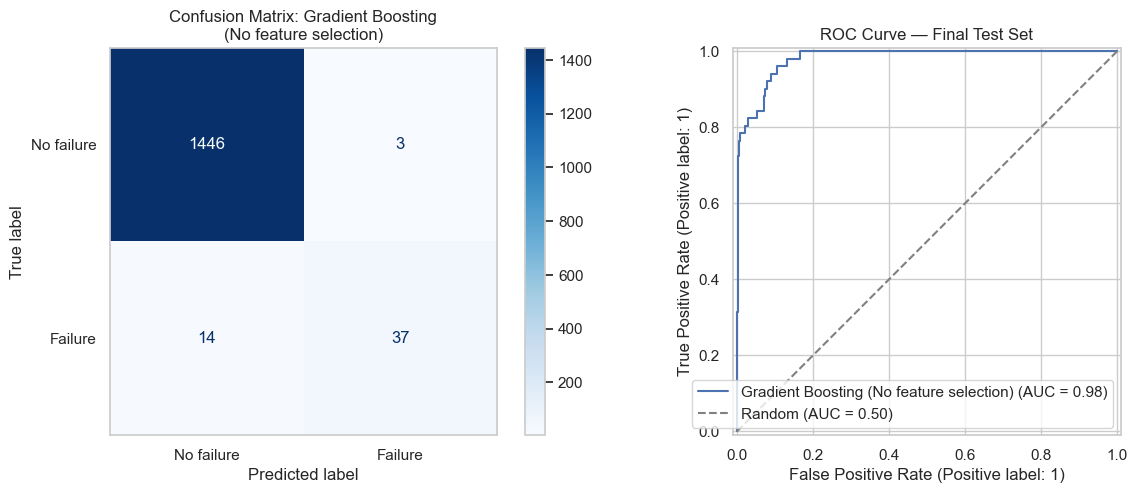

In [81]:
final_test_result = evaluate_on_split(
    final_estimator,
    final_metadata,
    final_result["Input features"],
    x_test,
    y_test,
    "Test",
    final_result["Features"],
)

print("Final unseen test result:")
display(
    pd.DataFrame([{
        key: value
        for key, value in final_test_result.items()
        if key != "Predictions"
    }])
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1) Confusion Matrix
cm = confusion_matrix(y_test, final_test_result["Predictions"], labels=[0, 1])
ConfusionMatrixDisplay(
    cm,
    display_labels=["No failure", "Failure"],
).plot(cmap="Blues", values_format="d", ax=axes[0])
axes[0].set_title(
    f"Confusion Matrix: {final_winner['Model']}\n({final_winner['Feature selection']})"
)
axes[0].grid(False)

# 2) ROC Curve & AUC
RocCurveDisplay.from_estimator(
    final_estimator,
    x_test[final_result["Input features"]],
    y_test,
    name=f"{final_winner['Model']} ({final_winner['Feature selection']})",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], ls="--", color="grey", label="Random (AUC = 0.50)")
axes[1].set_title("ROC Curve — Final Test Set")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


 ## 18. Term Project Conclusion and Recommendations



 This project demonstrates a complete, leak-free supervised machine learning workflow:



 1. **Explore & Preprocess:** Inspected the AI4I 2020 dataset, visualized physical failure boundaries, encoded `Type`, and removed target-leaking failure mode columns.

 2. **Strict Data Partitioning:** Split the data into 70% Training, 15% Validation, and 15% Test sets.

 3. **Feature Selection & Dimensionality Reduction:** Compared Filter (ANOVA, Pearson), Embedded (Adapted Lasso, Ridge, Elastic Net), Wrapper (RFE, Forward/Backward SFS), and PCA methods fitted strictly on the training set.

 4. **Candidate Screening & Stacking:** Screened 6 model families across all feature sets on the Validation split, selected the Top 3 distinct architectures, and tested a dynamic Stacking Ensemble.

 5. **Hyperparameter Fine-Tuning:** Tuned the Top 3 finalists using 5-Fold Stratified Cross-Validation on the training split.

 6. **Final Unseen Evaluation:** Refit the validation winner on the 85% development set and evaluated once on the 15% test set using F1, Recall, Precision, Balanced Accuracy, Confusion Matrix, and ROC-AUC.

## 19. Experiment Run Logger & Summary Exporter

Run the cell below every time you test a new configuration in **Section 7 (Master Experiment Configuration)**. It automatically:
1. **Appends** your current configuration, selected feature sets, Top 3 screening finalists, Stacking comparison, tuned winner, and final Test metrics to a cumulative text log (`experiment_runs_log.txt`) so you never lose previous runs.
2. **Generates** a clean, readable Markdown report (`latest_experiment_report.md`) and a multi-page **PDF summary (`experiment_summary.pdf`)** with comparison tables and charts so your team can easily compare approaches and pick the best one for your class presentation.

In [82]:
from datetime import datetime
from matplotlib.backends.backend_pdf import PdfPages

timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# 1. Build a clean text/markdown summary of the current configuration & results
run_summary_lines = [
    "=" * 80,
    f"EXPERIMENT RUN LOG — {timestamp}",
    "=" * 80,
    "",
    "1. MASTER CONFIGURATION SETTINGS:",
    f"   - RANDOM_STATE           : {RANDOM_STATE}",
    f"   - NUMBER_OF_FEATURES     : {NUMBER_OF_FEATURES}",
    f"   - RFE_SELECTOR_MODEL     : {RFE_SELECTOR_MODEL}",
    f"   - SFS_SELECTOR_MODEL     : {SFS_SELECTOR_MODEL}",
    f"   - PCA_VARIANCE           : {PCA_VARIANCE} ({pca.n_components_} components kept)",
    f"   - CV_FOLDS               : {CV_FOLDS}",
    f"   - UNIQUE_FINALIST_MODELS : {UNIQUE_FINALIST_MODELS}",
    "",
    "2. FEATURES SELECTED BY EACH METHOD:",
    f"   - Baseline (All 6)       : {', '.join(x_train.columns)}",
    f"   - ANOVA                  : {', '.join(anova_features)}",
    f"   - Pearson Correlation    : {', '.join(correlation_features)}",
    f"   - Adapted Lasso (L1)     : {', '.join(lasso_features)}",
    f"   - RFE ({RFE_SELECTOR_MODEL}) : {', '.join(rfe_features)}",
    f"   - Forward SFS ({SFS_SELECTOR_MODEL}) : {', '.join(forward_features)}",
    f"   - Backward SFS ({SFS_SELECTOR_MODEL}): {', '.join(backward_features)}",
    f"   - PCA ({PCA_VARIANCE*100:.0f}% var)        : {pca.n_components_} orthogonal components",
    "",
    "3. BEST MODEL PER FEATURE-SELECTION METHOD (VALIDATION SCREENING):",
    best_per_selection[[
        "Feature selection", "Model", "Validation failure F1",
        "Validation failure recall", "Validation failure precision",
        "Validation missed failures", "Validation false alarms"
    ]].to_string(index=False),
    "",
    "4. STACKING ENSEMBLE VS. TOP-1 INDIVIDUAL MODEL (VALIDATION):",
    comparison_df[[
        "Feature selection", "Model", "Validation failure F1",
        "Validation failure recall", "Validation failure precision",
        "Validation missed failures", "Validation false alarms"
    ]].to_string(index=False),
    "",
    "5. TOP 3 FINALISTS AFTER 5-FOLD CV HYPERPARAMETER TUNING (VALIDATION):",
    validation_finalist_results.drop(columns=["Predictions"])[[
        "Feature selection", "Model", "Validation F1",
        "Validation recall", "Validation precision",
        "Validation missed failures", "Validation false alarms"
    ]].to_string(index=False),
    "",
    "6. SELECTED WINNER & TUNED HYPERPARAMETERS:",
    f"   - Winning Model          : {final_winner['Model']}",
    f"   - Winning Feature Method : {final_winner['Feature selection']} ({final_result['Features']})",
    f"   - Best Hyperparameters   : {final_result['Best parameters']}",
    "",
    "7. FINAL UNSEEN TEST SET PERFORMANCE (EVALUATED ONCE):",
    f"   - Test Failure F1        : {final_test_result['Test F1']:.4f}",
    f"   - Test Failure Recall    : {final_test_result['Test recall']:.4f}",
    f"   - Test Failure Precision : {final_test_result['Test precision']:.4f}",
    f"   - Test Balanced Accuracy : {final_test_result['Test balanced accuracy']:.4f}",
    f"   - Test Missed Failures   : {final_test_result['Test missed failures']}",
    f"   - Test False Alarms      : {final_test_result['Test false alarms']}",
    "=" * 80,
    "\n"
]

report_text = "\n".join(run_summary_lines)

# 2. Append to cumulative text log (keeps history of all configurations you test!)
log_txt_path = "./Report/experiment_runs_log.txt"
with open(log_txt_path, "a", encoding="utf-8") as f:
    f.write(report_text)

# 3. Save a clean single-run Markdown report for easy reading in VS Code
md_path = "./Report/latest_experiment_report.md"
with open(md_path, "w", encoding="utf-8") as f:
    f.write(f"# Experiment Summary Report ({timestamp})\n\n```text\n{report_text}\n```\n")

# # 4. Export a visual PDF report (Text Summary + Bar Chart + Confusion Matrix & ROC)
# pdf_path = "experiment_summary.pdf"
# with PdfPages(pdf_path) as pdf:
#     # Page 1: Full Text Summary & Tables
#     fig_text = plt.figure(figsize=(11, 14))
#     fig_text.clf()
#     fig_text.text(
#         0.03, 0.97, report_text,
#         family="monospace", fontsize=8.5, va="top", ha="left"
#     )
#     plt.axis("off")
#     pdf.savefig(fig_text, bbox_inches="tight")
#     plt.close(fig_text)

#     # Page 2: Visual Comparison of Best Validation F1 per Feature Selection Method
#     fig_bar, ax_bar = plt.subplots(figsize=(10, 5))
#     plot_df = best_per_selection.sort_values("Validation failure F1", ascending=True)
#     labels = plot_df["Feature selection"].astype(str) + " (" + plot_df["Model"] + ")"
#     bars = ax_bar.barh(labels, plot_df["Validation failure F1"], color="steelblue")
#     for bar in bars:
#         w = bar.get_width()
#         ax_bar.text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center")
#     ax_bar.set_xlim(0, 1.05)
#     ax_bar.set_xlabel("Validation Failure F1-Score")
#     ax_bar.set_title(
#         f"Best Model per Feature Selection Method (k={NUMBER_OF_FEATURES}, RFE={RFE_SELECTOR_MODEL}, SFS={SFS_SELECTOR_MODEL})"
#     )
#     plt.tight_layout()
#     pdf.savefig(fig_bar, bbox_inches="tight")
#     plt.close(fig_bar)

#     # Page 3: Final Test Confusion Matrix & ROC Curve
#     fig_eval, axes_eval = plt.subplots(1, 2, figsize=(12, 5))
#     cm_pdf = confusion_matrix(y_test, final_test_result["Predictions"], labels=[0, 1])
#     ConfusionMatrixDisplay(cm_pdf, display_labels=["No failure", "Failure"]).plot(
#         cmap="Blues", values_format="d", ax=axes_eval[0]
#     )
#     axes_eval[0].set_title(f"Test Confusion Matrix: {final_winner['Model']}\n({final_winner['Feature selection']})")
#     axes_eval[0].grid(False)

#     RocCurveDisplay.from_estimator(
#         final_estimator,
#         x_test[final_result["Input features"]],
#         y_test,
#         name=f"{final_winner['Model']} ({final_winner['Feature selection']})",
#         ax=axes_eval[1],
#     )
#     axes_eval[1].plot([0, 1], [0, 1], ls="--", color="grey", label="Random (AUC = 0.50)")
#     axes_eval[1].set_title("Test Set ROC Curve")
#     axes_eval[1].legend(loc="lower right")
#     plt.tight_layout()
#     pdf.savefig(fig_eval, bbox_inches="tight")
#     plt.close(fig_eval)

print(f"Saved cumulative log to : {log_txt_path}")
print(f"Saved Markdown report to: {md_path}")
# print(f"Saved PDF report to     : {pdf_path}\n")
print(report_text)

Saved cumulative log to : ./Report/experiment_runs_log.txt
Saved Markdown report to: ./Report/latest_experiment_report.md
EXPERIMENT RUN LOG — 2026-10-14 20:28:15

1. MASTER CONFIGURATION SETTINGS:
   - RANDOM_STATE           : 55
   - NUMBER_OF_FEATURES     : 4
   - RFE_SELECTOR_MODEL     : Logistic Regression
   - SFS_SELECTOR_MODEL     : Decision Tree
   - PCA_VARIANCE           : 0.95 (4 components kept)
   - CV_FOLDS               : 5
   - UNIQUE_FINALIST_MODELS : True

2. FEATURES SELECTED BY EACH METHOD:
   - Baseline (All 6)       : Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min]
   - ANOVA                  : Air temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min]
   - Pearson Correlation    : Torque [Nm], Tool wear [min], Air temperature [K], Rotational speed [rpm]
   - Adapted Lasso (L1)     : Torque [Nm], Rotational speed [rpm], Air temperature [K], Tool wear [min]
   - RFE (Logistic Regression) : Air